# Freight Rate Prediction: Full Walkthrough

**Task.** Predict the price (`posted_rate`) of a truck load.
- **Training data:** 48,000 loads from **Jan–Oct 2025**, with prices.
- **To predict:** 12,000 loads from **Nov–Dec 2025** (no prices given).
- **Also required:** fill in a 31-day **December chart** for one fixed load (Lexington → Fort Wayne, 360 mi, Dry Van, 32,000 lb).

**How this notebook is organised.** It follows the investigation in the order it happened:
1. Look at the data and find problems
2. Find what drives prices over time
3. Experiment with model designs (tested honestly on "future" months)
4. Train the final model, predict, and make the December chart

Each step ends with a **💡 What we learn** note.

In [1]:
import subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.linear_model import LinearRegression, Ridge

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

# Use the GPU if this machine has one (Slurm GPU node), otherwise CPU.
DEVICE = "cuda" if subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0 else "cpu"
print("XGBoost device:", DEVICE)
if DEVICE == "cuda":
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout)

XGBoost device: cuda
NVIDIA L40, 46068 MiB



---
# Part 1: Look at the data

## 1.1 Load the files

In [2]:
train = pd.read_csv("data/train_test.csv", parse_dates=["date"])
valid = pd.read_csv("data/validation.csv", parse_dates=["date"])
december = pd.read_csv("data/december_chart_inputs.csv")

print("train:", train.shape, "| valid:", valid.shape, "| december:", december.shape)
train.head()

train: (48000, 14) | valid: (12000, 13) | december: (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
print("Columns in validation.csv:", list(valid.columns))
print("Columns in december_chart_inputs.csv:", list(december.columns))

Columns in validation.csv: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
Columns in december_chart_inputs.csv: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


💡 **What we learn**
- Each load has: route (pickup/delivery city + coordinates), `distance`, `equipment` (truck type), `weight`, `date`, `market_index`, `quote_signal`.
- `validation.csv` has the same columns, just without the price.
- **The December chart file has no `market_index`, `quote_signal` or coordinates.** We will need to fill those in ourselves later.

## 1.2 What dates do the files cover?

In [4]:
print("train dates:", train.date.min().date(), "→", train.date.max().date())
print("valid dates:", valid.date.min().date(), "→", valid.date.max().date())
pd.concat([train.date.dt.to_period("M").value_counts().sort_index().rename("train loads"),
           valid.date.dt.to_period("M").value_counts().sort_index().rename("valid loads")], axis=1).fillna(0).astype(int).T

train dates: 2025-01-01 → 2025-10-31
valid dates: 2025-11-01 → 2025-12-31


date,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
train loads,4918,4337,5036,4819,4913,4783,4912,4759,4670,4853,0,0
valid loads,0,0,0,0,0,0,0,0,0,0,5836,6164


💡 **What we learn: this is the most important finding.**
Every load we must predict is in **Nov–Dec**, *after* all the training data (Jan–Oct). So this is a **forecasting** problem:
- We must test the model the same way: learn from earlier months, predict later months. A random split would cheat.
- The model must handle prices that keep moving over time.

## 1.3 Missing values and basic statistics

In [5]:
print("Missing values (train):", train.isna().sum()[lambda s: s > 0].to_dict())
print("Missing values (valid):", valid.isna().sum()[lambda s: s > 0].to_dict())
train.describe().T.round(2)

Missing values (train): {'weight': 300, 'market_index': 374}
Missing values (valid): {'weight': 165, 'market_index': 249}


,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.399999,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


💡 **What we learn**
- `weight`: some values missing, the **minimum is −47,500** (negative weights are impossible), and the max is exactly 47,500 (looks like a cap).
- `market_index`: ~370 missing values.
- `posted_rate`: ranges from **$57 to $25,533**. Suspicious, so let's look at price per mile.

## 1.4 Are some prices wrong? (price per mile)

In [6]:
train["rate_per_mile"] = train.posted_rate / train.distance
# Compare each load to the typical price-per-mile of its truck type
train["ratio_to_typical"] = train.rate_per_mile / train.groupby("equipment").rate_per_mile.transform("median")

buckets = pd.cut(train.ratio_to_typical, [0, 0.2, 0.3, 0.5, 0.7, 0.8, 1.25, 1.5, 2, 4, 8, 20])
buckets.value_counts().sort_index().to_frame("number of loads")

,number of loads
ratio_to_typical,
"(0.0, 0.2]",36
"(0.2, 0.3]",153
"(0.3, 0.5]",144
"(0.5, 0.7]",4
"(0.7, 0.8]",92
"(0.8, 1.25]",45017
"(1.25, 1.5]",2195
"(1.5, 2.0]",21
"(2.0, 4.0]",223


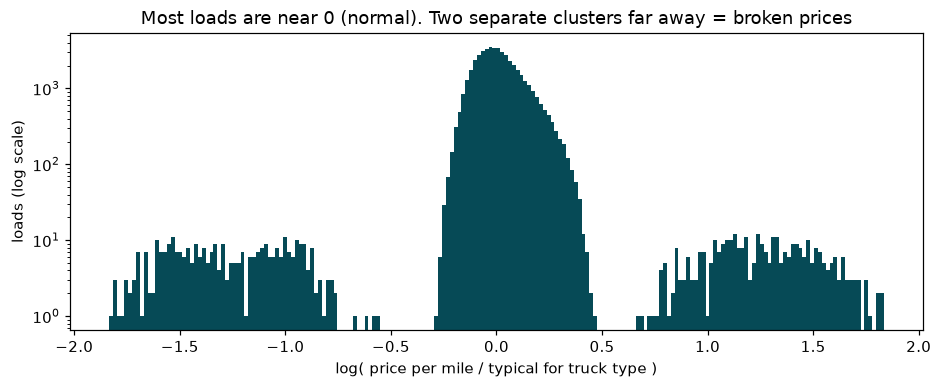

Examples of suspiciously LOW prices:


,pickup,delivery,distance,equipment,posted_rate,rate_per_mile
50,Los Angeles,Green Bay,2202.5,Reefer,1243.45,0.564563
190,Tampa,Milwaukee,919.8,Dry Van,704.89,0.766351
294,Greensboro,Syracuse,685.6,Dry Van,518.31,0.755995
439,Richmond,Charleston,394.9,Dry Van,276.27,0.699595
508,Las Vegas,Grand Rapids,1976.4,Flatbed,699.41,0.353881


Examples of suspiciously HIGH prices:


,pickup,delivery,distance,equipment,posted_rate,rate_per_mile
388,Corpus Christi,Chattanooga,823.0,Flatbed,5485.49,6.665237
785,Kansas City,Charleston,861.5,Dry Van,4587.83,5.325398
870,Tulsa,Baton Rouge,305.6,Reefer,4069.24,13.315576
1149,Houston,Baton Rouge,170.3,Flatbed,1359.60,7.983558
1175,Tucson,Phoenix,260.5,Dry Van,1609.22,6.177428


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(np.log(train.ratio_to_typical), bins=200, color="#064A56")
ax.set_yscale("log"); ax.set_xlabel("log( price per mile / typical for truck type )"); ax.set_ylabel("loads (log scale)")
ax.set_title("Most loads are near 0 (normal). Two separate clusters far away = broken prices")
plt.show()
print("Examples of suspiciously LOW prices:")
display(train[train.ratio_to_typical < 0.5][["pickup", "delivery", "distance", "equipment", "posted_rate", "rate_per_mile"]].head(5))
print("Examples of suspiciously HIGH prices:")
display(train[train.ratio_to_typical > 2.5][["pickup", "delivery", "distance", "equipment", "posted_rate", "rate_per_mile"]].head(5))

💡 **What we learn**
- ~96% of loads cost about $1.8–2.8 per mile, which is normal.
- **~1.2% of prices are clearly broken**: either about **4× too high** or about **0.3× too low** (e.g. a 920-mile load for $705). They form separate clusters with a clear gap, so they look like data-entry errors, not real prices.
- **Decision:** remove them from training (no model can learn from them), and leave them out when measuring error.

## 1.5 Mark the broken prices with a simple rule
Long loads naturally have a lower price per mile, so instead of a fixed threshold we compare each price with a simple formula based on distance and truck type. Anything more than e^0.5 ≈ 1.65× away from it is flagged.

In [8]:
X = pd.get_dummies(train.equipment).astype(float).assign(log_dist=np.log(train.distance))
resid = np.log(train.posted_rate) - LinearRegression().fit(X, np.log(train.posted_rate)).predict(X)
train["bad_label"] = np.abs(resid - np.median(resid)) > 0.5
print(f"Flagged {train.bad_label.sum()} of {len(train)} loads ({train.bad_label.mean():.1%}) as broken prices")

Flagged 677 of 48000 loads (1.4%) as broken prices


## 1.6 Weight: what do the negative values mean?

In [9]:
clean = train[~train.bad_label]
w_bucket = pd.cut(clean.weight, [-50000, 0, 10000, 20000, 30000, 40000, 47499, 47501],
                  labels=["negative", "0-10k", "10-20k", "20-30k", "30-40k", "40-47.5k", "=47.5k (cap)"])
clean.groupby(w_bucket, observed=True).ratio_to_typical.agg(["count", "mean"]).round(3)

,count,mean
weight,,
negative,283,1.026
0-10k,199,0.968
10-20k,3494,0.979
20-30k,16332,0.998
30-40k,19752,1.035
40-47.5k,5791,1.050
=47.5k (cap),1175,1.052


💡 **What we learn**
- Heavier loads cost slightly more (+3–5%).
- **Negative-weight loads are priced like heavy loads (~30k lb)**, not like empty trucks. So the minus sign is a typo. **Fix:** take the absolute value.
- Missing weights: XGBoost can handle missing values natively, so we leave them as missing.

## 1.7 Cities: are there cities in Nov–Dec we never saw?

In [10]:
seen = set(train.pickup) | set(train.delivery)
new_cities = sorted((set(valid.pickup) | set(valid.delivery)) - seen)
print(f"{len(new_cities)} cities in validation never appear in training: {new_cities}")
n_new = (valid.pickup.isin(new_cities) | valid.delivery.isin(new_cities)).sum()
print(f"{n_new} validation loads ({n_new/len(valid):.1%}) involve a new city")

# Does each city always have the same coordinates?
both = pd.concat([train, valid])
print("Cities with more than one coordinate:",
      (both.groupby("pickup")[["pickup_lat", "pickup_lon"]].nunique() > 1).any(axis=1).sum())

8 cities in validation never appear in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
1447 validation loads (12.1%) involve a new city
Cities with more than one coordinate: 0


💡 **What we learn**
- 8 new cities, involved in about **12%** of validation loads. If the model used city *names*, it would know nothing about these.
- **Decision:** use **latitude/longitude** instead of city names. A new city is still "somewhere on the map", so the model can use what it learned about nearby cities.
- Each city has one fixed coordinate, so we can also build a city → coordinates lookup for the December chart file.

## 1.8 Distance vs straight-line distance

In [11]:
def haversine_miles(d):
    lat1, lon1, lat2, lon2 = (np.radians(d[c]) for c in ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))

ratio = train.distance / haversine_miles(train)
print(ratio.describe().round(3))
print("\nLoads where road distance > 2x straight line:", (ratio > 2).sum())

count    48000.000
mean         1.195
std          0.144
min          1.058
25%          1.165
50%          1.182
75%          1.205
max          9.635
dtype: float64

Loads where road distance > 2x straight line: 22


💡 **What we learn**
- Road distance ≈ **1.18 × straight-line distance**, as expected (roads aren't straight).
- A handful of loads have odd distances (some are clipped at a minimum of 70 miles). Too few to matter; we give the model **both** distances and let it decide.

---
# Part 2: What makes prices go up and down over time?

## 2.1 The market index

Spread of market_index WITHIN the same day : 0.025
Spread of the daily average ACROSS days    : 0.165


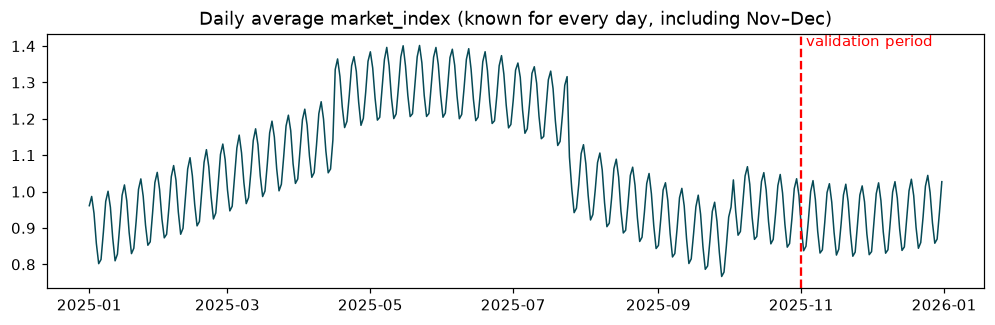

Autocorrelation by lag (days): {1: np.float64(0.92), 2: np.float64(0.75), 3: np.float64(0.61), 4: np.float64(0.6), 5: np.float64(0.73), 6: np.float64(0.9), 7: np.float64(0.97), 8: np.float64(0.89), 9: np.float64(0.72), 10: np.float64(0.58), 11: np.float64(0.57), 12: np.float64(0.7), 13: np.float64(0.87), 14: np.float64(0.94)}


In [12]:
both = pd.concat([train, valid])
within_day = both.groupby("date").market_index.std().mean()
across_days = both.groupby("date").market_index.mean().std()
print(f"Spread of market_index WITHIN the same day : {within_day:.3f}")
print(f"Spread of the daily average ACROSS days    : {across_days:.3f}")

mi_by_day = both.groupby("date").market_index.mean()
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(mi_by_day.index, mi_by_day.values, color="#064A56", lw=1)
ax.axvline(pd.Timestamp("2025-11-01"), color="red", ls="--"); ax.text(pd.Timestamp("2025-11-03"), 1.4, "validation period", color="red")
ax.set_title("Daily average market_index (known for every day, including Nov–Dec)"); plt.show()
print("Autocorrelation by lag (days):", {k: round(np.log(mi_by_day).autocorr(k), 2) for k in range(1, 15)})

💡 **What we learn**
- `market_index` is basically **one number per day** (it barely varies within a day). **Fix for missing values:** use that day's average.
- It has a strong **weekly cycle**: the autocorrelation peaks at 7 and 14 days.
- **It's known for every day of Nov–Dec too** (from validation.csv), so we can use it for the December chart.

## 2.2 Strip out distance and truck type, then look at the daily price level
A simple formula explains most of each price from distance, truck type, weight and quote signal. What's left over (the *residual*) shows what the date adds on top. We average that per day.

In [13]:
clean = train[~train.bad_label].copy()
X = pd.get_dummies(clean.equipment).astype(float)
X["log_dist"] = np.log(clean.distance); X["log_dist2"] = X.log_dist ** 2
X["weight"] = clean.weight.abs().fillna(clean.weight.abs().median()) / 1e4
X["quote_signal"] = clean.quote_signal
y = np.log(clean.posted_rate)
clean["resid"] = y - LinearRegression().fit(X, y).predict(X)
print(f"Typical per-load error of this simple formula: {clean.resid.std():.1%}")

print("\nAverage leftover by day of week (0=Mon):", clean.groupby(clean.date.dt.dayofweek).resid.mean().round(4).to_dict())
print("\nAverage leftover by month:")
print((100 * clean.groupby(clean.date.dt.month).resid.mean()).round(1).to_dict())

Typical per-load error of this simple formula: 4.4%

Average leftover by day of week (0=Mon): {0: -0.0088, 1: -0.0013, 2: 0.0077, 3: 0.0104, 4: 0.0061, 5: -0.0039, 6: -0.0108}

Average leftover by month:
{1: -5.4, 2: -4.0, 3: -0.5, 4: 0.2, 5: 2.5, 6: 4.5, 7: 2.1, 8: -1.1, 9: 0.3, 10: 0.9}


💡 **What we learn**
- Day of week: only a small ±1% wiggle. As we'll see, that's just the market index's weekly cycle.
- Month matters a lot: from **−5.4%** in January to **+4.5%** in June. Prices move over time. Is that just the market index, or something more?

## 2.3 How much of the daily level does the market index explain?

In [14]:
daily = clean.groupby("date").agg(level=("resid", "mean")).join(mi_by_day.rename("mi"))
daily["log_mi"] = np.log(daily.mi)
daily["t"] = (daily.index - pd.Timestamp("2025-01-01")).days / 365           # time in years
daily["qramp"] = (daily.index.month % 3 == 0) * (daily.index.day - 1) / (daily.index.days_in_month - 1)

r = LinearRegression().fit(daily[["log_mi"]], daily.level)
print(f"level ~ market_index         R² = {r.score(daily[['log_mi']], daily.level):.2f}")
r = LinearRegression().fit(daily[["log_mi", "t"]], daily.level)
print(f"level ~ market_index + time  R² = {r.score(daily[['log_mi', 't']], daily.level):.2f}   (time coef = {r.coef_[1]:.3f} → ~{r.coef_[1]:.0%}/year rise)")
daily["leftover"] = daily.level - r.predict(daily[["log_mi", "t"]])

level ~ market_index         R² = 0.49
level ~ market_index + time  R² = 0.86   (time coef = 0.078 → ~8%/year rise)


💡 **What we learn**
- The market index alone explains only **49%** of the daily price level.
- Adding a simple **time trend** raises this to **86%**: prices drift up by about **7–8% per year** on top of the market index.
- There is still some pattern left. Let's look at the leftover as a calendar heat-map.

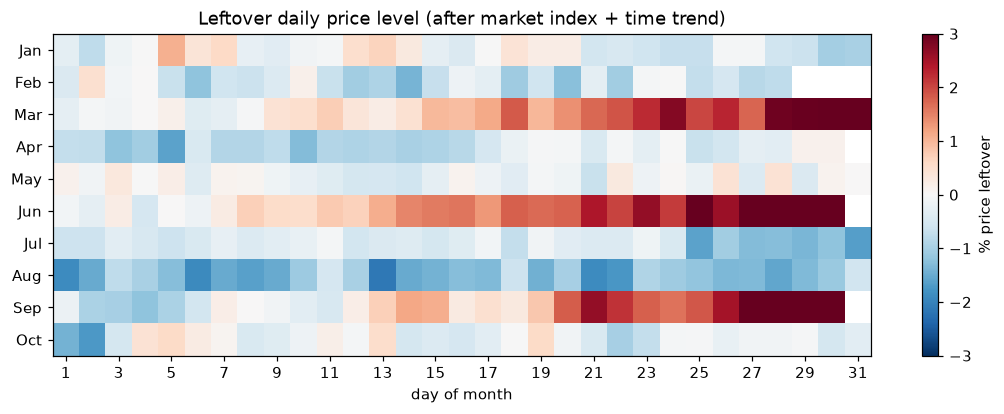

In [15]:
pivot = daily.assign(month=daily.index.month, day=daily.index.day).pivot(index="month", columns="day", values="leftover") * 100
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(pivot.values, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(len(pivot.index)), [pd.Timestamp(2025, m, 1).strftime("%b") for m in pivot.index])
ax.set_xticks(range(0, 31, 2), range(1, 32, 2)); ax.set_xlabel("day of month")
plt.colorbar(im, label="% price leftover"); ax.set_title("Leftover daily price level (after market index + time trend)")
plt.show()

💡 **What we learn: a big discovery.**
**March, June and September** go from blue (cheap) at the start of the month to red (expensive) at the end, then reset the next month. Those are the **last months of each quarter**.

This is a known effect in trucking: companies rush to ship goods before the quarter closes, so trucks get scarce and prices climb. **December is also a quarter-end month**, so this matters for our forecast and for the December chart.

We model it as a **"quarter-end ramp"**: 0 on day 1 of Mar/Jun/Sep/Dec, rising linearly to 1 on the last day, and 0 in all other months.

level ~ market_index + time + quarter-end ramp   R² = 0.968
coefficients: {'log_mi': np.float64(0.155), 't': np.float64(0.074), 'qramp': np.float64(0.037)}
remaining day-to-day noise: 0.55%


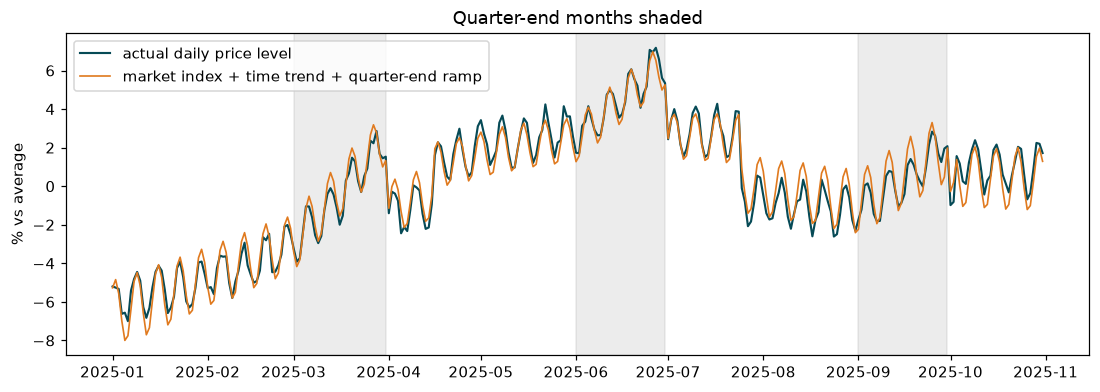

In [16]:
cols = ["log_mi", "t", "qramp"]
r = LinearRegression().fit(daily[cols], daily.level)
print(f"level ~ market_index + time + quarter-end ramp   R² = {r.score(daily[cols], daily.level):.3f}")
print("coefficients:", dict(zip(cols, r.coef_.round(3))))
print(f"remaining day-to-day noise: {np.std(daily.level - r.predict(daily[cols])):.2%}")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, 100 * daily.level, color="#064A56", lw=1.4, label="actual daily price level")
ax.plot(daily.index, 100 * r.predict(daily[cols]), color="#E07A1F", lw=1.1, label="market index + time trend + quarter-end ramp")
for m in [3, 6, 9]:
    ax.axvspan(pd.Timestamp(2025, m, 1), pd.Timestamp(2025, m, 1) + pd.offsets.MonthEnd(1), color="grey", alpha=0.15)
ax.set_ylabel("% vs average"); ax.legend(loc="upper left"); ax.set_title("Quarter-end months shaded"); plt.show()

💡 **What we learn**
Three simple ingredients explain **97%** of how prices move from day to day:
1. **Market index**: +0.15% price for each +1% market index (the weekly wiggle)
2. **Time trend**: about +7% per year
3. **Quarter-end ramp**: about +4% by the end of Mar/Jun/Sep

The orange line almost exactly traces the real one. These are the effects we must **carry forward** into Nov–Dec.

## 2.4 Does the quarter-end effect differ by truck type or region?

In [17]:
clean["log_mi"] = np.log(clean.date.map(mi_by_day))
clean["t"] = (clean.date - pd.Timestamp("2025-01-01")).dt.days / 365
clean["qramp"] = (clean.date.dt.month % 3 == 0) * (clean.date.dt.day - 1) / (clean.date.dt.days_in_month - 1)
clean["log_mi_dev"] = np.log(clean.market_index) - clean.log_mi    # this load's index vs the day's average

rows = []
for name, g in clean.groupby("equipment"):
    c = LinearRegression().fit(g[["log_mi", "t", "qramp"]], g.resid).coef_
    rows.append({"group": name, "market_index": c[0], "time trend": c[1], "quarter-end ramp": c[2]})
for name, g in clean.groupby(pd.cut(clean.pickup_lon, [-130, -100, -90, -80, -60], labels=["West", "Central", "East-Central", "East"])):
    c = LinearRegression().fit(g[["log_mi", "t", "qramp"]], g.resid).coef_
    rows.append({"group": f"pickup region: {name}", "market_index": c[0], "time trend": c[1], "quarter-end ramp": c[2]})
display(pd.DataFrame(rows).round(3))

g = clean.dropna(subset=["log_mi_dev"])
c = LinearRegression().fit(g[["log_mi", "log_mi_dev"]], g.resid).coef_
print(f"Effect of the day's market index: {c[0]:.3f} | effect of this load's own deviation from it: {c[1]:.3f}")

,group,market_index,time trend,quarter-end ramp
0,Dry Van,0.154,0.072,0.023
1,Flatbed,0.153,0.077,0.071
2,Reefer,0.160,0.075,0.042
3,pickup region: West,0.160,0.071,0.037
4,pickup region: Central,0.156,0.077,0.035
5,pickup region: East-Central,0.153,0.074,0.034
6,pickup region: East,0.152,0.073,0.040


Effect of the day's market index: 0.141 | effect of this load's own deviation from it: 0.129


💡 **What we learn**
- Market index effect and time trend are the **same for every truck type and region**.
- **The quarter-end ramp is not the same:** about **+2.3% for Dry Van**, +4.2% for Reefer and +7.1% for Flatbed. **Decision:** give the ramp a separate strength per truck type.
- A load's own market index (vs the day's average) also matters, with a similar effect. **Decision:** include it.

---
# Part 3: Experiments to choose the model

## 3.1 How we test: time-series cross-validation ("walk-forward")
To mimic the real task (learn Jan–Oct, predict Nov–Dec), each test hides two "future" months:

| Test | Learn from | Predict |
|---|---|---|
| 1 | Jan–Apr | May–Jun |
| 2 | Jan–Jun | Jul–Aug |
| 3 | Jan–Aug | Sep–Oct |

The main measure is **MAPE**, the average % error. We also report **bias**: whether predictions are too high (+) or too low (−) on average. Broken prices are removed from training and from scoring.

In [18]:
city = pd.concat([d[[f"{s}", f"{s}_lat", f"{s}_lon"]].set_axis(["city", "lat", "lon"], axis=1)
                  for d in [train, valid] for s in ["pickup", "delivery"]]).groupby("city").first()

def make_features(df):
    d = df.copy()
    d["date"] = pd.to_datetime(d["date"])
    d["weight"] = d["weight"].abs()                                    # negative weight = sign typo
    d["mi_day"] = d.date.map(mi_by_day)
    if "market_index" not in d: d["market_index"] = np.nan             # December chart rows
    d["market_index"] = d.market_index.fillna(d.mi_day)                 # missing -> day's average
    if "quote_signal" not in d: d["quote_signal"] = train.quote_signal.median()
    for s in ["pickup", "delivery"]:                                    # December chart rows: look up coordinates
        if f"{s}_lat" not in d: d[f"{s}_lat"], d[f"{s}_lon"] = d[s].map(city.lat), d[s].map(city.lon)
    for e, col in [("Dry Van", "is_dryvan"), ("Reefer", "is_reefer"), ("Flatbed", "is_flatbed")]:
        d[col] = (d.equipment == e).astype(float)
    d["log_distance"] = np.log(d.distance)
    d["straight_line_miles"] = haversine_miles(d)
    d["log_mi_day"] = np.log(d.mi_day)
    d["log_mi_dev"] = np.log(d.market_index) - d.log_mi_day
    d["t"] = (d.date - pd.Timestamp("2025-01-01")).dt.days / 365
    d["qramp"] = (d.date.dt.month % 3 == 0) * (d.date.dt.day - 1) / (d.date.dt.days_in_month - 1)
    d["qramp_reefer"], d["qramp_flatbed"] = d.qramp * d.is_reefer, d.qramp * d.is_flatbed
    return d

F = make_features(train)
F["bad_label"] = train.bad_label.values
FOLDS = [("2025-05-01", "2025-06-30"), ("2025-07-01", "2025-08-31"), ("2025-09-01", "2025-10-31")]
XGB_PARAMS = dict(n_estimators=3000, learning_rate=0.02, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, tree_method="hist", device=DEVICE)

def backtest(fit_predict, name):
    """fit_predict(train_df, test_df) -> predicted prices. Runs the 3 time folds and scores clean test loads."""
    out = {}
    for start, end in FOLDS:
        past = F[(F.date < start) & ~F.bad_label]
        future = F[(F.date >= start) & (F.date <= end) & ~F.bad_label]
        p, a = fit_predict(past, future), future.posted_rate.values
        out[f"{start[5:7]}-{end[5:7]} MAPE%"] = 100 * np.mean(np.abs(p / a - 1))
        out[f"{start[5:7]}-{end[5:7]} bias%"] = 100 * np.mean(np.log(p / a))
    out["AVG MAPE%"] = np.mean([v for k, v in out.items() if "MAPE" in k])
    return pd.Series(out, name=name).round(2)

results = []

## 3.2 Experiment A: the obvious approach, plain XGBoost on all features

In [19]:
ALL_FEATURES = ["is_dryvan", "is_reefer", "is_flatbed", "distance", "log_distance", "straight_line_miles",
                "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "weight",
                "market_index", "mi_day", "quote_signal"]

def xgb_plain(a, b):
    m = xgb.XGBRegressor(**XGB_PARAMS).fit(a[ALL_FEATURES], np.log(a.posted_rate))
    return np.exp(m.predict(b[ALL_FEATURES]))

results.append(backtest(xgb_plain, "A: XGBoost, all features"))
pd.DataFrame(results)

,05-06 MAPE%,05-06 bias%,07-08 MAPE%,07-08 bias%,09-10 MAPE%,09-10 bias%,AVG MAPE%
"A: XGBoost, all features",2.22,-1.57,3.1,-1.66,3.39,-3.33,2.9


💡 **What we learn**
- Average error **2.9%**, and it gets **worse the further into the year** we forecast. It is also always **too low** (negative bias), reaching **−3.3%** in Sep–Oct.
- **Why:** prices rise over the year, but a tree model can only output values similar to what it has already seen. It cannot continue a trend into the future.

## 3.3 Experiment B: give XGBoost a 'time' feature

In [20]:
def xgb_with_time(a, b):
    cols = ALL_FEATURES + ["t"]
    m = xgb.XGBRegressor(**XGB_PARAMS).fit(a[cols], np.log(a.posted_rate))
    return np.exp(m.predict(b[cols]))

results.append(backtest(xgb_with_time, "B: XGBoost + time feature"))
pd.DataFrame(results)

,05-06 MAPE%,05-06 bias%,07-08 MAPE%,07-08 bias%,09-10 MAPE%,09-10 bias%,AVG MAPE%
"A: XGBoost, all features",2.22,-1.57,3.10,-1.66,3.39,-3.33,2.90
B: XGBoost + time feature,2.70,-1.81,4.27,0.41,2.17,-1.65,3.05


💡 **What we learn**
No better overall (3.05% average): it helps in Sep–Oct but hurts in Jul–Aug. For any future date, a tree just uses the **last time value it saw** (it treats every future date like the last day of training). It still can't continue the trend.

## 3.4 Experiment C: two-part model, a linear formula for time effects + XGBoost for the rest
**Idea:** a linear formula *can* continue a trend ("+7%/year" works for any date). So:
1. A **linear model** learns the time effects (market index, time trend, and the quarter-end ramp).
2. **XGBoost** learns what the linear model got wrong (the "leftover"), using the load features.
3. Prediction = linear + XGBoost.

We try a few versions to see which ingredients matter.

In [21]:
def two_part(linear_cols, tree_cols):
    def fit_predict(a, b):
        y = np.log(a.posted_rate)
        lin = Ridge(alpha=1e-3).fit(a[linear_cols], y)
        trees = xgb.XGBRegressor(**XGB_PARAMS).fit(a[tree_cols], y - lin.predict(a[linear_cols]))
        return np.exp(lin.predict(b[linear_cols]) + trees.predict(b[tree_cols]))
    return fit_predict

BASE_LIN = ["is_reefer", "is_flatbed", "log_distance", "log_mi_day"]
results.append(backtest(two_part(BASE_LIN + ["t"], ALL_FEATURES), "C1: linear(market + time) + XGB(all)"))
results.append(backtest(two_part(BASE_LIN + ["t", "qramp"], ALL_FEATURES), "C2: linear(market + time + qtr ramp) + XGB(all)"))
pd.DataFrame(results)

,05-06 MAPE%,05-06 bias%,07-08 MAPE%,07-08 bias%,09-10 MAPE%,09-10 bias%,AVG MAPE%
"A: XGBoost, all features",2.22,-1.57,3.10,-1.66,3.39,-3.33,2.90
B: XGBoost + time feature,2.70,-1.81,4.27,0.41,2.17,-1.65,3.05
C1: linear(market + time) + XGB(all),1.62,0.38,4.70,4.24,1.66,-0.95,2.66
C2: linear(market + time + qtr ramp) + XGB(all),1.46,0.10,2.83,1.74,1.56,-0.04,1.95


💡 **What we learn**
- C1 (time trend without the quarter ramp) **overshoots** in Jul–Aug: training ended at the expensive end of June, so the trend line came out too steep.
- C2 (adding the quarter-end ramp) fixes that: average error drops to **1.95%** (from 2.9% for plain XGBoost), with bias within ±1.8%.
- Can we do better?
- **Suspicion:** XGBoost still sees `market_index` and `mi_day`. Since the market index differs from day to day, the trees can use it to **recognise the date** and memorise each period's price level. That again doesn't carry forward to new dates.

## 3.5 Experiment D: XGBoost sees only the load features, with no date or market info

In [22]:
LOAD_FEATURES = ["is_dryvan", "is_reefer", "is_flatbed", "distance", "log_distance", "straight_line_miles",
                 "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "weight", "quote_signal"]

results.append(backtest(two_part(BASE_LIN + ["t", "qramp"], LOAD_FEATURES), "D1: linear(market+time+ramp) + XGB(load only)"))
results.append(backtest(two_part(BASE_LIN + ["t", "qramp"], LOAD_FEATURES + ["market_index"]), "D2: same, but XGB also sees market_index"))
pd.DataFrame(results)

,05-06 MAPE%,05-06 bias%,07-08 MAPE%,07-08 bias%,09-10 MAPE%,09-10 bias%,AVG MAPE%
"A: XGBoost, all features",2.22,-1.57,3.10,-1.66,3.39,-3.33,2.90
B: XGBoost + time feature,2.70,-1.81,4.27,0.41,2.17,-1.65,3.05
C1: linear(market + time) + XGB(all),1.62,0.38,4.70,4.24,1.66,-0.95,2.66
C2: linear(market + time + qtr ramp) + XGB(all),1.46,0.10,2.83,1.74,1.56,-0.04,1.95
D1: linear(market+time+ramp) + XGB(load only),1.40,0.29,2.11,1.58,1.51,-0.67,1.67
"D2: same, but XGB also sees market_index",1.39,0.26,2.57,1.71,1.56,-0.20,1.84


💡 **What we learn: the winning design.**
- Removing market/date information from XGBoost lowers the error again: **1.95% → 1.67%**. Each part now has a clear job:
  - **Linear part:** *when* the load ships (market, trend, quarter-end). It carries forward.
  - **XGBoost:** *what* the load is (distance, route, weight, truck type). This doesn't change over time, so nothing needs carrying forward.
- Giving XGBoost the market index back (D2) makes things worse again (1.84%), which confirms the suspicion.

## 3.6 Experiment E: final refinements from Part 2.4 (ramp per truck type + the load's own market index)

In [23]:
FINAL_LINEAR = ["is_reefer", "is_flatbed", "log_distance", "log_mi_day", "log_mi_dev",
                "t", "qramp", "qramp_reefer", "qramp_flatbed"]
results.append(backtest(two_part(FINAL_LINEAR, LOAD_FEATURES), "E: FINAL (ramp per truck type + load market index)"))
summary = pd.DataFrame(results)
summary.to_csv("outputs/experiments.csv")   # used by make_report.py
summary

,05-06 MAPE%,05-06 bias%,07-08 MAPE%,07-08 bias%,09-10 MAPE%,09-10 bias%,AVG MAPE%
"A: XGBoost, all features",2.22,-1.57,3.10,-1.66,3.39,-3.33,2.90
B: XGBoost + time feature,2.70,-1.81,4.27,0.41,2.17,-1.65,3.05
C1: linear(market + time) + XGB(all),1.62,0.38,4.70,4.24,1.66,-0.95,2.66
C2: linear(market + time + qtr ramp) + XGB(all),1.46,0.10,2.83,1.74,1.56,-0.04,1.95
D1: linear(market+time+ramp) + XGB(load only),1.40,0.29,2.11,1.58,1.51,-0.67,1.67
"D2: same, but XGB also sees market_index",1.39,0.26,2.57,1.71,1.56,-0.20,1.84
E: FINAL (ramp per truck type + load market index),1.33,0.18,2.10,1.61,1.43,-0.67,1.62


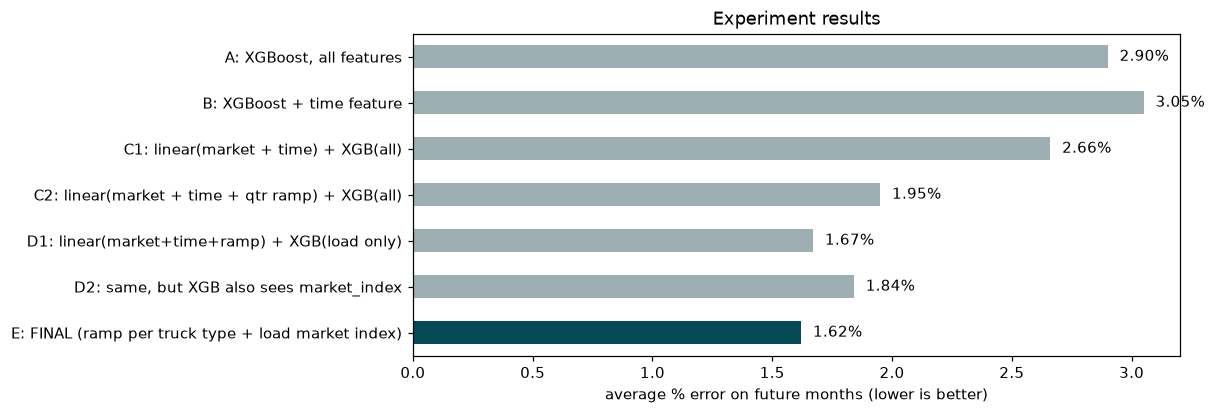

In [24]:
ax = summary["AVG MAPE%"].iloc[::-1].plot.barh(figsize=(9, 3.8), color=["#064A56" if i == 0 else "#9DAFB3" for i in range(len(summary))])
ax.set_xlabel("average % error on future months (lower is better)"); ax.set_title("Experiment results")
for i, v in enumerate(summary["AVG MAPE%"].iloc[::-1]): ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
plt.show()

💡 **What we learn**
The refinements help a little more (**1.62%**). **Final design = E**, with about **45% less error** than plain XGBoost (2.90%).

## 3.7 What is the best error we could hope for? (noise floor)
If we cheat with a **random** split (the model sees loads from the same days it's tested on), there is no forecasting involved. That gives a "best possible" reference.

In [25]:
rng = np.random.default_rng(0)
ok = F[~F.bad_label]
is_train = rng.random(len(ok)) < 0.8
p = two_part(FINAL_LINEAR, LOAD_FEATURES)(ok[is_train], ok[~is_train])
a = ok[~is_train].posted_rate.values
print(f"Random-split MAPE (no forecasting needed): {100*np.mean(np.abs(p/a-1)):.2f}%")
pd.Series({"random_split_mape": 100*np.mean(np.abs(p/a-1))}).to_csv("outputs/noise_floor.csv")   # used by make_report.py

Random-split MAPE (no forecasting needed): 1.25%


💡 **What we learn**
- Even when cheating, the error is about **1.25%**. That is the natural noise in prices (two identical loads won't cost exactly the same).
- Our honest forecasting error is **1.3–2.1%** (1.62% average), so the model is **close to the best possible**.
- It also shows why a random split is misleading: it would make any model look better than it really is at forecasting.

## 3.8 Experiment F: how should broken prices be removed?
My first version of `train.py` let the model find broken prices itself: train on everything, flag the loads it misses badly, remove them, train again. Here we compare that with the simple rule from 1.5, scoring both on exactly the same test rows.

In [26]:
def self_flagging(a, b):
    y = np.log(a.posted_rate)                                     # pass 1: train on ALL rows (incl. broken)
    lin = Ridge(alpha=1e-3).fit(a[FINAL_LINEAR], y)
    trees = xgb.XGBRegressor(**XGB_PARAMS).fit(a[LOAD_FEATURES], y - lin.predict(a[FINAL_LINEAR]))
    miss = np.abs(y - lin.predict(a[FINAL_LINEAR]) - trees.predict(a[LOAD_FEATURES]))
    p = two_part(FINAL_LINEAR, LOAD_FEATURES)(a[miss <= 0.4], b)  # pass 2: drop rows missed by > e^0.4
    return p, miss.values

rows = []
for start, end in FOLDS:
    past, future = F[F.date < start], F[(F.date >= start) & (F.date <= end) & ~F.bad_label]
    p_self, miss = self_flagging(past, future)
    p_rule = two_part(FINAL_LINEAR, LOAD_FEATURES)(past[~past.bad_label], future)
    a = future.posted_rate.values
    rows.append({"predict": f"{start} → {end}",
                 "MAPE % (model flags its own misses)": 100 * np.mean(np.abs(p_self / a - 1)),
                 "MAPE % (simple rule)": 100 * np.mean(np.abs(p_rule / a - 1)),
                 "broken prices the model MISSED": int((past.bad_label.values & (miss <= 0.4)).sum())})
expF = pd.DataFrame(rows)
expF.to_csv("outputs/experiment_f.csv", index=False)   # used by make_report.py
expF.round(2)

,predict,MAPE % (model flags its own misses),MAPE % (simple rule),broken prices the model MISSED
0,2025-05-01 → 2025-06-30,2.98,1.33,123
1,2025-07-01 → 2025-08-31,2.86,2.10,81
2,2025-09-01 → 2025-10-31,1.68,1.43,54


💡 **What we learn: a bug in my first version.**
- XGBoost is powerful enough to partly **memorise** the broken prices during the first pass. Their errors look smaller than they really are, so some are **not flagged** and stay in the training data.
- Each broken price is off by ~4×. With squared error that counts thousands of times more than a normal load, so the 50–120 that slip through per test pull the model off badly.
- The simple rule can't memorise anything, so it catches them all, and the error drops a lot.
- **Decision:** the final `train.py` uses the simple rule.

---
# Part 4: Final model (same as `train.py`)

## 4.1 The model (exactly what `train.py` does)
1. Remove broken prices with the simple rule (Experiment F).
2. Linear model learns the market/time effects.
3. XGBoost learns what the linear model got wrong, from the load features only.
4. Prediction = exp(linear + XGBoost).

In [27]:
class FreightModel:
    """log(price) = Linear(market + time effects) + XGBoost(load features)"""
    def fit(self, d):
        d = d[~d.bad_label]                                                          # never learn from broken prices
        y = np.log(d.posted_rate)
        self.linear = Ridge(alpha=1e-3).fit(d[FINAL_LINEAR], y)                     # step 1: time effects
        leftover = y - self.linear.predict(d[FINAL_LINEAR])
        self.trees = xgb.XGBRegressor(**XGB_PARAMS).fit(d[LOAD_FEATURES], leftover)  # step 2: load effects
        return self

    def predict(self, d):
        return np.exp(self.linear.predict(d[FINAL_LINEAR]) + self.trees.predict(d[LOAD_FEATURES]))

## 4.2 Final walk-forward check (same numbers `train.py` reports)

In [28]:
rows = []
for start, end in FOLDS:
    past, future = F[F.date < start], F[(F.date >= start) & (F.date <= end)]
    p, a, ok = FreightModel().fit(past).predict(future), future.posted_rate.values, ~future.bad_label.values
    rows.append({"learn": f"Jan → {pd.Timestamp(start) - pd.Timedelta(days=1):%b}", "predict": f"{start} → {end}",
                 "MAE $": np.mean(np.abs(p[ok] - a[ok])), "MAPE %": 100 * np.mean(np.abs(p[ok] / a[ok] - 1)),
                 "bias %": 100 * np.mean(np.log(p[ok] / a[ok])), "broken prices skipped": int((~ok).sum())})
bt = pd.DataFrame(rows)
bt.loc[len(bt)] = {"learn": "AVERAGE", "predict": "", **bt.mean(numeric_only=True)}
bt.round(2)

,learn,predict,MAE $,MAPE %,bias %,broken prices skipped
0,Jan → Apr,2025-05-01 → 2025-06-30,32.30,1.33,0.18,125
1,Jan → Jun,2025-07-01 → 2025-08-31,50.91,2.10,1.61,133
2,Jan → Aug,2025-09-01 → 2025-10-31,32.81,1.43,-0.67,144
3,AVERAGE,,38.67,1.62,0.38,134


💡 **What we learn**
- On average the model is off by about **1.6%** (≈ **$39** per load).
- Bias stays within ±1.6%, so there is no systematic over- or under-pricing.

## 4.3 Train on ALL of Jan–Oct and look inside the model

In [29]:
final = FreightModel().fit(F)
print(f"Removed {F.bad_label.sum()} broken prices out of {len(F)}\n")
print("Linear part (effect on log price):")
pd.Series(final.linear.coef_, index=FINAL_LINEAR).round(4).to_frame("coefficient")

Removed 677 broken prices out of 48000

Linear part (effect on log price):


,coefficient
is_reefer,0.1177
is_flatbed,0.0722
log_distance,0.8714
log_mi_day,0.1538
log_mi_dev,0.1412
t,0.0731
qramp,0.0243
qramp_reefer,0.0246
qramp_flatbed,0.0530


💡 **How to read this**
- `log_mi_day` 0.15: market index +10% → price +1.5%
- `t` 0.074: prices rise about 7.4% per year
- `qramp` 0.024: Dry Van prices rise +2.4% by the end of a quarter-end month (Reefer +4.9%, Flatbed +7.7%)
- `log_distance` 0.87: double the distance → price ×1.8 (longer trips are cheaper *per mile*)

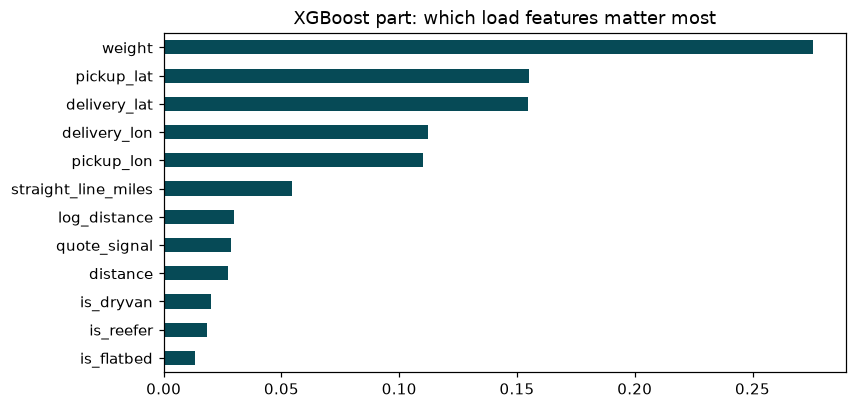

In [30]:
imp = pd.Series(final.trees.feature_importances_, index=LOAD_FEATURES).sort_values()
imp.plot.barh(figsize=(8, 4), color="#064A56", title="XGBoost part: which load features matter most"); plt.show()

## 4.4 Predict the 12,000 Nov–Dec loads

In [31]:
V = make_features(valid)
template = pd.read_csv("data/validation_predictions_template.csv")
pred = pd.Series(final.predict(V), index=V.load_id)
template["predicted_rate"] = template.load_id.map(pred).round(2)
template[["load_id", "predicted_rate"]].to_csv("validation_predictions.csv", index=False)

print("Saved validation_predictions.csv:", template.shape, "| missing:", template.predicted_rate.isna().sum())
display(template.head())
pd.concat([train.posted_rate[~train.bad_label].describe().rename("train actual prices (clean)"),
           template.predicted_rate.describe().rename("Nov–Dec predictions")], axis=1).round(0)

Saved validation_predictions.csv: (12000, 2) | missing: 0


,load_id,predicted_rate
0,TE-000001,840.59
1,TE-000002,5207.00
2,TE-000003,5212.59
3,TE-000004,4083.10
4,TE-000005,1846.02


,train actual prices (clean),Nov–Dec predictions
count,47323.0,12000.0
mean,2347.0,2397.0
std,1354.0,1386.0
min,185.0,191.0
25%,1262.0,1290.0
50%,2032.0,2072.0
75%,3314.0,3401.0
max,7498.0,7062.0


💡 **What we learn**
The predictions have a very similar range and spread to the real training prices, so there are no crazy values.

## 4.5 The December chart
Fixed load: Lexington → Fort Wayne, 360 mi, Dry Van, 32,000 lb. Only the date changes.
The file is missing a few inputs, which we fill as follows:
- **coordinates:** from the city lookup
- **market_index:** that day's average from validation.csv
- **quote_signal:** the training median

In [32]:
dec = pd.read_csv("data/december_chart_inputs.csv")[["pickup", "delivery", "distance", "equipment", "weight", "date"]]
dec["predicted_rate"] = final.predict(make_features(dec)).round(2)
dec.to_csv("data/december_chart_inputs.csv", index=False)
dec[["date", "predicted_rate"]].T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
date,2025-12-01,2025-12-02,2025-12-03,2025-12-04,2025-12-05,2025-12-06,2025-12-07,2025-12-08,2025-12-09,2025-12-10,2025-12-11,2025-12-12,2025-12-13,2025-12-14,2025-12-15,...,2025-12-17,2025-12-18,2025-12-19,2025-12-20,2025-12-21,2025-12-22,2025-12-23,2025-12-24,2025-12-25,2025-12-26,2025-12-27,2025-12-28,2025-12-29,2025-12-30,2025-12-31
predicted_rate,821.9,834.36,845.96,850.69,845.16,834.09,826.23,828.52,840.64,852.6,857.14,852.01,841.09,833.27,835.57,...,859.07,864.08,859.02,847.81,840.08,843.33,854.47,866.83,871.57,866.25,855.66,848.17,850.77,862.46,874.62


## 4.6 Run the provided `score.py` (checks file formats and draws the official chart)

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



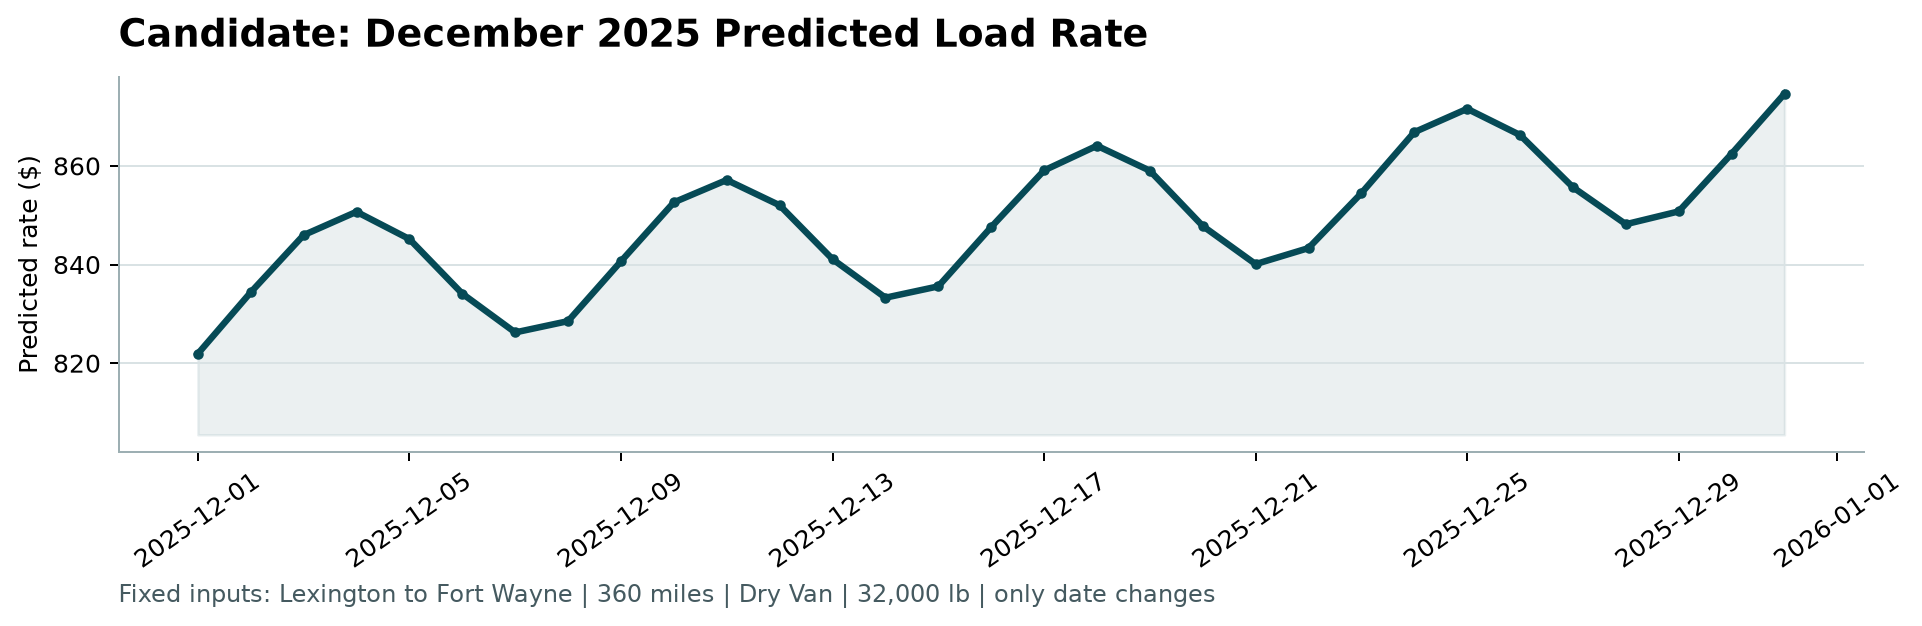

In [33]:
print(subprocess.run([".venv/bin/python", "score.py", "--predictions", "validation_predictions.csv",
                      "--december-predictions", "data/december_chart_inputs.csv"], capture_output=True, text=True).stdout)
from IPython.display import Image
Image("scorer_results/candidate_december.png", width=900)

💡 **How to read the chart**
- **Weekly wiggle:** comes from the market index's weekly cycle.
- **Steady climb through the month:** the yearly upward trend plus the **December quarter-end ramp** (+2.4% for Dry Van by Dec 31).

## 4.7 Sanity check: what did real loads on this lane cost?

In [34]:
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne") & (train.equipment == "Dry Van") & ~train.bad_label]
display(lane[["date", "distance", "weight", "market_index", "posted_rate"]].tail(8))
print(f"Real prices on this lane (Apr–Oct): ${lane.posted_rate.min():.0f} – ${lane.posted_rate.max():.0f}")
print(f"Our December predictions:           ${dec.predicted_rate.min():.0f} – ${dec.predicted_rate.max():.0f}")

,date,distance,weight,market_index,posted_rate
23524,2025-05-29,378.8,39179.0,1.38372,934.37
26302,2025-06-15,359.7,19949.0,1.23523,824.39
31113,2025-07-15,362.5,36951.0,1.26556,880.63
35557,2025-08-13,360.8,22007.0,1.06957,796.71
40765,2025-09-15,350.9,22972.0,0.81021,778.24
43271,2025-10-01,371.4,26829.0,0.90458,841.42
47076,2025-10-26,363.0,17917.0,0.83786,796.48
47722,2025-10-30,370.3,26358.0,1.01336,864.61


Real prices on this lane (Apr–Oct): $758 – $934
Our December predictions:           $822 – $875


💡 **What we learn**
The December predictions fall right inside the range of real prices on this exact lane, so the model's output is believable.

---
# Summary

| | |
|---|---|
| **Problem** | Forecast Nov–Dec truck prices from Jan–Oct history |
| **Data fixes** | Removed ~1.4% broken prices (×4 / ×0.3) with a simple rule; negative weight → positive; missing market index → day's average; coordinates instead of city names (8 new cities) |
| **Key discovery** | Price level over time = market index + ~7%/yr trend + quarter-end ramp (explains 97% of the daily level) |
| **Model** | Linear part for time effects (it carries trends forward) + XGBoost on load features only |
| **Testing** | Walk-forward: learn the past, predict the next 2 months, 3 times |
| **Result** | **1.62% average error** (≈ $39/load) vs **2.90%** for plain XGBoost; best possible ≈ 1.25% |